In [1]:
import os

os.listdir()

['.ipynb_checkpoints',
 'epa-sea-level.csv',
 'sea_level_predictor.ipynb',
 'Untitled.ipynb']

In [2]:
import pandas as pd

In [3]:
df=pd.read_csv("epa-sea-level.csv")

In [4]:
df.head(10)

,Year,CSIRO Adjusted Sea Level,Lower Error Bound,Upper Error Bound,NOAA Adjusted Sea Level
0,1880,0.000000,-0.952756,0.952756,NaN
1,1881,0.220472,-0.732283,1.173228,NaN
2,1882,-0.440945,-1.346457,0.464567,NaN
3,1883,-0.232283,-1.129921,0.665354,NaN
4,1884,0.590551,-0.283465,1.464567,NaN
5,1885,0.531496,-0.330709,1.393701,NaN
6,1886,0.437008,-0.381890,1.255906,NaN
7,1887,0.216535,-0.602362,1.035433,NaN
8,1888,0.299213,-0.519685,1.118110,NaN
9,1889,0.362205,-0.456693,1.181102,NaN


In [5]:
df.columns

Index(['Year', 'CSIRO Adjusted Sea Level', 'Lower Error Bound',
       'Upper Error Bound', 'NOAA Adjusted Sea Level'],
      dtype='str')

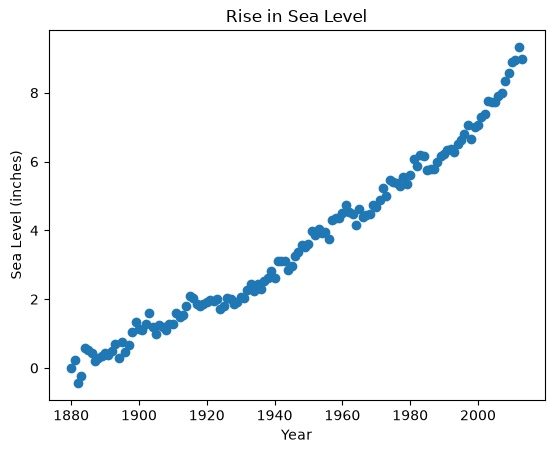

In [6]:
import matplotlib.pyplot as plt

plt.scatter(
    df["Year"],
    df["CSIRO Adjusted Sea Level"]
)

plt.xlabel("Year")
plt.ylabel("Sea Level (inches)")
plt.title("Rise in Sea Level")

plt.show()

In [7]:
result = linregress(
    df["Year"],
    df["CSIRO Adjusted Sea Level"]
)

NameError: name 'linregress' is not defined

In [8]:
from scipy.stats import linregress

ModuleNotFoundError: No module named 'scipy'

In [9]:
from scipy.stats import linregress

ModuleNotFoundError: No module named 'scipy'

In [18]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

In [3]:
df = pd.read_csv("epa-sea-level.csv")

In [4]:
df.head(10)

,Year,CSIRO Adjusted Sea Level,Lower Error Bound,Upper Error Bound,NOAA Adjusted Sea Level
0,1880,0.000000,-0.952756,0.952756,NaN
1,1881,0.220472,-0.732283,1.173228,NaN
2,1882,-0.440945,-1.346457,0.464567,NaN
3,1883,-0.232283,-1.129921,0.665354,NaN
4,1884,0.590551,-0.283465,1.464567,NaN
5,1885,0.531496,-0.330709,1.393701,NaN
6,1886,0.437008,-0.381890,1.255906,NaN
7,1887,0.216535,-0.602362,1.035433,NaN
8,1888,0.299213,-0.519685,1.118110,NaN
9,1889,0.362205,-0.456693,1.181102,NaN


In [5]:
result = linregress(
    df["Year"],
    df["CSIRO Adjusted Sea Level"]
)

In [6]:
result.slope

np.float64(0.06304458401213482)

In [7]:
result.intercept

np.float64(-119.06594196773983)

In [8]:
years = range(1880, 2051)

In [9]:
predicted = [
    result.slope * year + result.intercept
    for year in years
]

In [10]:
predicted[-1]

np.float64(10.175455257136548)

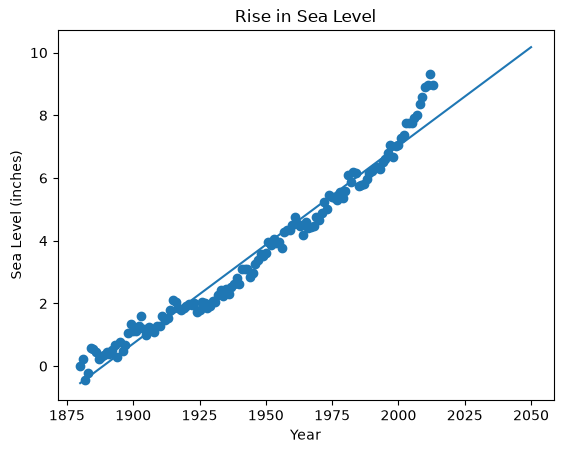

In [11]:
plt.scatter(
    df["Year"],
    df["CSIRO Adjusted Sea Level"]
)

plt.plot(
    years,
    predicted
)

plt.xlabel("Year")
plt.ylabel("Sea Level (inches)")
plt.title("Rise in Sea Level")

plt.show()

In [12]:
df_2000 = df[df["Year"] >= 2000]

In [13]:
df_2000.head()

,Year,CSIRO Adjusted Sea Level,Lower Error Bound,Upper Error Bound,NOAA Adjusted Sea Level
120,2000,7.062992,6.791339,7.334646,6.920582
121,2001,7.287402,7.019685,7.555118,7.087460
122,2002,7.381890,7.110236,7.653543,7.319698
123,2003,7.759843,7.484252,8.035433,7.488353
124,2004,7.740157,7.464567,8.015748,7.507933


In [14]:
result_2000 = linregress(
    df_2000["Year"],
    df_2000["CSIRO Adjusted Sea Level"]
)

In [18]:
result_2000.slope

np.float64(0.16642727333186821)

In [19]:
result_2000.intercept

np.float64(-325.79346680596495)

In [20]:
years_2000 = range(2000, 2051)

In [21]:
predicted_2000 = [
    result_2000.slope * year + result_2000.intercept
    for year in years_2000
]

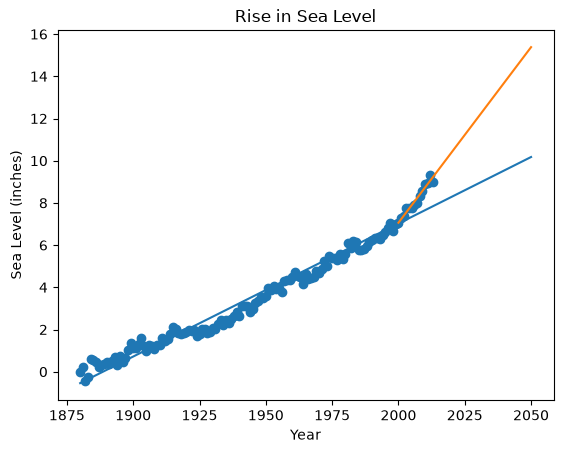

In [22]:
plt.scatter(
    df["Year"],
    df["CSIRO Adjusted Sea Level"]
)

# First regression line: 1880 to 2050
plt.plot(
    years,
    predicted
)

# Second regression line: 2000 to 2050
plt.plot(
    years_2000,
    predicted_2000
)

plt.xlabel("Year")
plt.ylabel("Sea Level (inches)")
plt.title("Rise in Sea Level")

plt.show()

In [23]:
plt.savefig("sea_level_plot.png")

<Figure size 640x480 with 0 Axes>

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress


def draw_plot():

    # Read data
    df = pd.read_csv("epa-sea-level.csv")

    # Create scatter plot
    plt.scatter(
        df["Year"],
        df["CSIRO Adjusted Sea Level"]
    )

    # First line of best fit
    result = linregress(
        df["Year"],
        df["CSIRO Adjusted Sea Level"]
    )

    years = range(1880, 2051)

    predicted = [
        result.slope * year + result.intercept
        for year in years
    ]

    plt.plot(
        years,
        predicted
    )

    # Second line of best fit
    df_2000 = df[df["Year"] >= 2000]

    result_2000 = linregress(
        df_2000["Year"],
        df_2000["CSIRO Adjusted Sea Level"]
    )

    years_2000 = range(2000, 2051)

    predicted_2000 = [
        result_2000.slope * year + result_2000.intercept
        for year in years_2000
    ]

    plt.plot(
        years_2000,
        predicted_2000
    )

    # Labels
    plt.xlabel("Year")
    plt.ylabel("Sea Level (inches)")
    plt.title("Rise in Sea Level")

    # Save plot
    plt.savefig("sea_level_plot.png")

    return plt.gca()

<Axes: title={'center': 'Rise in Sea Level'}, xlabel='Year', ylabel='Sea Level (inches)'>

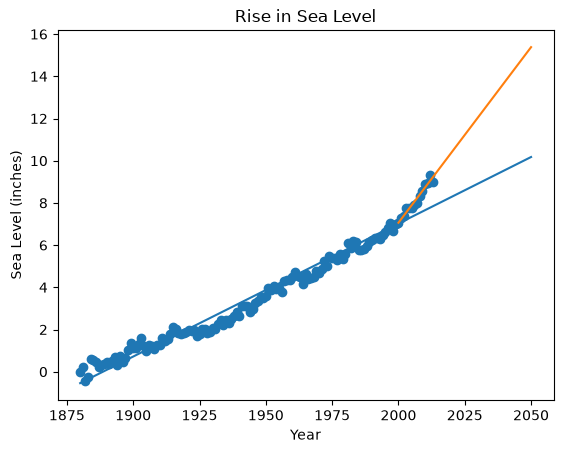

In [25]:
draw_plot()

In [26]:
from sea_level_predictor import draw_plot

<Axes: title={'center': 'Rise in Sea Level'}, xlabel='Year', ylabel='Sea Level (inches)'>

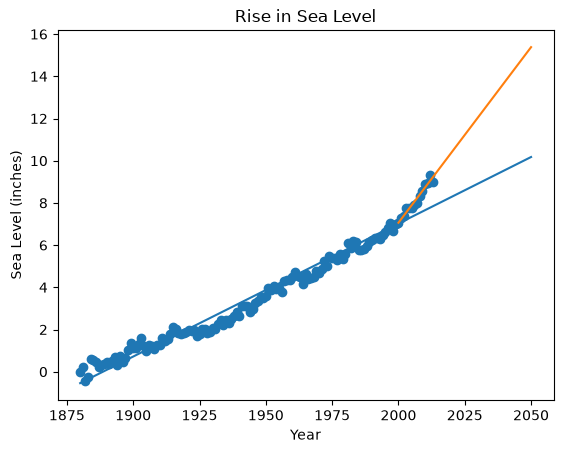

In [27]:
draw_plot()